In [ ]:
# Check whether previous model objects are available
for name in [
    "rf", "rf_model", "random_forest",
    "best_rf", "X_train", "X_test",
    "y_train", "y_test"
]:
    print(f"{name}: {'Available' if name in globals() else 'Not found'}")

rf: Not found
rf_model: Not found
random_forest: Not found
best_rf: Not found
X_train: Available
X_test: Available
y_train: Available
y_test: Available


In [ ]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("\nTraining variable types:")
print(X_train.dtypes)

print("\nMissing values in training data:")
print(X_train.isnull().sum().sum())

print("\nFirst five rows:")
display(X_train.head())

X_train shape: (3269, 7)
X_test shape: (1402, 7)

Training variable types:
RIDAGEYR                                 float64
sex_Male                                    bool
race_ethnicity_Non-Hispanic Asian           bool
race_ethnicity_Non-Hispanic Black           bool
race_ethnicity_Non-Hispanic White           bool
race_ethnicity_Other Hispanic               bool
race_ethnicity_Other Race/Multiracial       bool
dtype: object

Missing values in training data:
0

First five rows:


,RIDAGEYR,sex_Male,race_ethnicity_Non-Hispanic Asian,race_ethnicity_Non-Hispanic Black,race_ethnicity_Non-Hispanic White,race_ethnicity_Other Hispanic,race_ethnicity_Other Race/Multiracial
543,65.0,False,False,False,True,False,False
302,62.0,False,False,False,False,True,False
2316,52.0,False,True,False,False,False,False
2964,74.0,False,False,False,True,False,False
947,64.0,True,False,True,False,False,False


In [ ]:
#Step 1. Train the Random Forest
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("\nTraining variable types:")
print(X_train.dtypes)

print("\nMissing values in training data:")
print(X_train.isnull().sum().sum())

print("\nFirst five rows:")
display(X_train.head())

X_train shape: (3269, 7)
X_test shape: (1402, 7)

Training variable types:
RIDAGEYR                                 float64
sex_Male                                    bool
race_ethnicity_Non-Hispanic Asian           bool
race_ethnicity_Non-Hispanic Black           bool
race_ethnicity_Non-Hispanic White           bool
race_ethnicity_Other Hispanic               bool
race_ethnicity_Other Race/Multiracial       bool
dtype: object

Missing values in training data:
0

First five rows:


,RIDAGEYR,sex_Male,race_ethnicity_Non-Hispanic Asian,race_ethnicity_Non-Hispanic Black,race_ethnicity_Non-Hispanic White,race_ethnicity_Other Hispanic,race_ethnicity_Other Race/Multiracial
543,65.0,False,False,False,True,False,False
302,62.0,False,False,False,False,True,False
2316,52.0,False,True,False,False,False,False
2964,74.0,False,False,False,True,False,False
947,64.0,True,False,True,False,False,False


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

y_prob = rf_model.predict_proba(X_test)[:, 1]

auc = roc_auc_score(y_test, y_prob)

print("Random Forest trained successfully!")
print(f"Test ROC-AUC: {auc:.3f}")

Random Forest trained successfully!
Test ROC-AUC: 0.695


The analysis revealed that the model has moderate ability to distinguish participants with heart disease from those without it, using only age, sex, and race/ethnicity. The AUC is .695. The next step is to caculate the build in features.

Built-in Feature Importance:


,Feature,Built_in_Importance
0,RIDAGEYR,0.895826
1,sex_Male,0.046554
4,race_ethnicity_Non-Hispanic White,0.014904
3,race_ethnicity_Non-Hispanic Black,0.012979
6,race_ethnicity_Other Race/Multiracial,0.010874
5,race_ethnicity_Other Hispanic,0.010102
2,race_ethnicity_Non-Hispanic Asian,0.008762


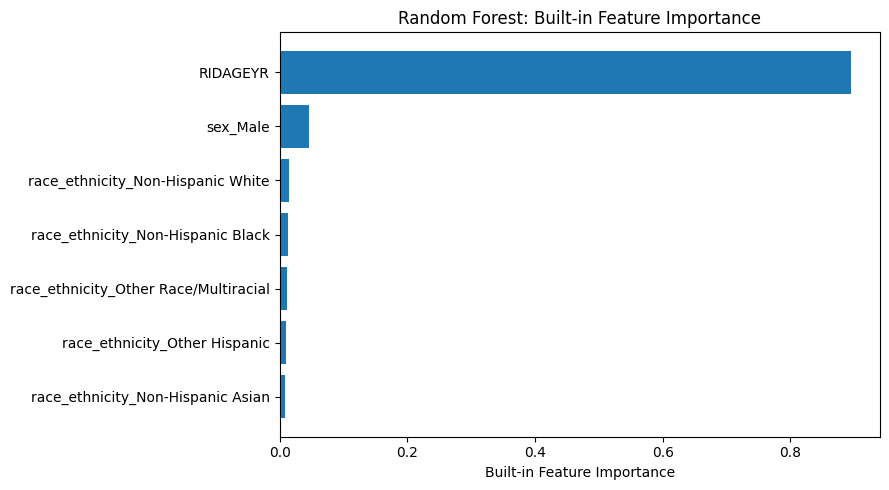

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Calculate built-in feature importance
built_in = pd.DataFrame({
    "Feature": X_train.columns,
    "Built_in_Importance": rf_model.feature_importances_
})

# Sort from most important to least important
built_in = built_in.sort_values(
    "Built_in_Importance", ascending=False
)

print("Built-in Feature Importance:")
display(built_in)

# Plot results
plt.figure(figsize=(9, 5))
plt.barh(
    built_in["Feature"],
    built_in["Built_in_Importance"]
)
plt.xlabel("Built-in Feature Importance")
plt.title("Random Forest: Built-in Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

Age accounts for approximately 89.6% of the total built-in importance in the Random Forest model. However, there is a methdological consideration that must be considered. Random Forest's standard built-in importance can favor continous variables like age because more potential splitting points are offered in comparison to binary variables.

In [ ]:
#Calculating permutation importance

from sklearn.inspection import permutation_importance
import pandas as pd

# Calculate permutation importance on held-out test data
perm = permutation_importance(
    rf_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="roc_auc",
    n_jobs=-1
)

# Create results table
perm_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Permutation_Importance": perm.importances_mean,
    "Standard_Deviation": perm.importances_std
})

# Sort by permutation importance
perm_df = perm_df.sort_values(
    "Permutation_Importance",
    ascending=False
)

print("Permutation Feature Importance:")
display(perm_df)

Permutation Feature Importance:


,Feature,Permutation_Importance,Standard_Deviation
0,RIDAGEYR,0.158428,0.025673
1,sex_Male,0.009039,0.012201
5,race_ethnicity_Other Hispanic,0.008075,0.003191
4,race_ethnicity_Non-Hispanic White,0.007152,0.009678
2,race_ethnicity_Non-Hispanic Asian,0.004355,0.003563
3,race_ethnicity_Non-Hispanic Black,-0.000665,0.003516
6,race_ethnicity_Other Race/Multiracial,-0.005948,0.002508


Although the Random Forest used the other/multiracial variable when constructing trees, shufflint it in the data slightly improved AUC on average than reducing it.

Overall findings: For this exercise, I used a Random Forest classifier to predict heart disease using demographic characteristics (age, sex, and race/ethnicity) from the NHANES dataset (N = 4,671). The model achieved a test AUC of .695. I then compared built-in feature importance with permutation importantion calculated on the held-out test dataset. Both methods identified as as the most important predictor. However, they differed in how they ranked several race/ethnicity indicators.

One disagreement involved the Other Race/Multiracial indicator, which ranked fifth in the built-in importance (0.0109) but last in permutation importance (-0.0059). Although the Random Forest used this variable to make splits during training, randomly shuffling it in the test data slightly imporoved model performance on average.

The difference shows us that a varible's contribution to constructing decsion trees does not necessarily translate into improved predictive performance on new data. It also highlights the importance of considering multiple apporaches to interpreting machine learning models, especially when examining demographic characteristics.